## **프로젝트 구조**

노트북 3개: ① `CubeRCNN_detection` (검출 시각화) · ② `OVMono3D_LIFT_rep` (B2 baseline) · ③ `STEP1_2A_final` (제안 방법)

```
소프트웨어융합캡스톤디자인/
├── 📁 Dataset/Final Dataset/                         (읽기만) train·val·test 영상, *_label.json
└── 📁 BoxSizing/
    ├── 📄 train / val / test_label_mapping.xlsx      (읽기만) 트랙 ↔ GT 수작업 매핑 (val 461쌍)
    ├── 📁 mapping_vis/                               수작업 매핑용 그림 (근거 자료)
    ├── 📁 wheels/torch2.11.0_cu130_py313/            ①에서 만든 설치 파일, ②가 재사용
    │   ├── detectron2-0.6-*.whl
    │   ├── 📁 pytorch3d_full/
    │   └── 📁 pytorch3d_noext/
    ├── 📁 checkpoints/
    │   ├── yolo26l_v5_augmentation.pt               상자 검출 (트래킹 캐시를 새로 만들 때만)
    │   ├── rail_seg_yolov8s_LabelStudio_best.pt     레일 세그멘테이션 (트래킹 캐시를 새로 만들 때만)
    │   ├── 📁 step13/1C_r18_geo_fold{0~4}.pt         ③ STEP 1 점유율 모델
    │   ├── 📁 step2/
    │   │   ├── 2A_*_fold{0~4}.pt                    ③ STEP 2-A 후보 (2A_cnv2n_rgb · 2A_rgb_fs 등)
    │   │   └── 2B*_fold{0~4}.pt                     10.15 STEP 2-B 비교용 (보존)
    │   ├── 📁 depth_anything_v3/DA3METRIC-LARGE.onnx 10.15 STEP 2-B 비교용 (보존)
    │   ├── 📁 cubercnn/                              ① omni3d_cubercnn_DLA34_FPN.pth, category_meta.json
    │   ├── 📁 ovmono3d/ovmono3d_lift.pth             ② 공식 가중치
    │   ├── 📁 hf_cache/hub/                          ② UniDepthV2 ViT-L (약 1.4GB), ovmono3d_lift 원본
    │   └── 📁 torch_cache/hub/                       ② DINOv2 코드 + dinov2_vitb14 가중치
    ├── 📁 cache/
    │   ├── 📁 train/ · val/ · test/*.pkl             (읽기만) 트래킹 + 레일 quad + ROI — 세 노트북 공용
    │   ├── step13_crops_{split}_area_224_p10.npz    ③ 상자 crop (대표 프레임 = bbox 면적 최대)
    │   └── step2_depth_* · step2_height_*           10.15 STEP 2-B 비교용 (보존)
    └── 📁 outputs/
        ├── 📁 step1/                                 ③
        │   ├── step1_pairs_mapped.csv               (트랙, GT) 쌍 + w_base + B_gt (train 899 · val 461)
        │   ├── step1_folds.csv                      영상 단위 5-fold 분할 (STEP 1·2 공용)
        │   ├── step13_preds.pkl · step2_preds.pkl   train OOF 예측 저장소
        │   ├── val_final_results.csv                [F-2] 최종 채점 표
        │   └── val_vs_baselines.csv                 [F-4] baseline과 같은 쌍 비교
        ├── 📁 step2/
        │   └── {split}_proposed_preds.csv           ③ [F-2]가 저장 → ② [F-1]이 읽음
        └── 📁 baseline/
            ├── 📁 cubercnn/                          ①
            │   ├── val_detection_vis.png            [V-1] 우리 bbox vs Cube R-CNN 검출 그림
            │   └── val_pairs.csv · val_roi_pairs.csv  이전 치수 비교 결과 (③ [F-4]가 읽음, 보존)
            └── 📁 ovmono3d_rep/                      ② B2 (트랙당 최대 bbox 1장)
                ├── raw_val/{video_id}.pkl           [R-2] val 원시 출력
                ├── raw_test/{video_id}.pkl          [R-3] test 원시 출력 (채점은 11/6)
                ├── val_track_preds.csv              [E-1] 트랙별 예측 (raw · rail_box · rail_global)
                ├── val_pairs.csv                    [E-1] 상수 기준선 + LIFT 쌍별 오차 → ③ [F-4]가 읽음
                ├── val_summary.csv · val_summary.json  [E-4] 결과표 + 스펙 + 설정 + 배율 S (test 채점 때 재사용)
                └── figs_val/                        [F-1] 비교 (상수 · B2 · 제안 방법)
                    ├── fig1_main_mae.png
                    ├── fig2_shape_ratio.png
                    ├── fig3_error_cdf.png
                    ├── fig4_side_bias.png
                    └── all_baselines_table.csv
```

# **Cube R-CNN (Omni3D, CVPR 2023) — 우리 상자를 검출하지 못한다**

> 단안 3D 검출의 대표 모델인 Cube R-CNN을 **공식 코드 · 공식 가중치 그대로** 우리 상차 CCTV 영상에 적용해 본다.
> 같은 프레임에 **우리 트래킹 bbox(초록)** 와 **Cube R-CNN 검출(빨강)** 을 겹쳐 그리면, 상자 자체가 검출되지 않는다는 것이 바로 보인다.
> → 그래서 **2D 검출 결과를 넘겨주면 3D를 추정하는 OVMono3D-LIFT**를 최신 논문 baseline으로 설정했다.

| 항목 | 설정 |
|---|---|
| 모델 | Cube R-CNN DLA34-FPN, Omni3D 전체 학습 공개 체크포인트 (fine-tune 없음) |
| 입력 | 원본 프레임 1280×720 그대로 + 카메라 내부 파라미터 (`f_px = focal_mm × 1280 / 5.79`, 주점 = 화면 중심) |
| 추론 | 공식 `demo/demo.py`와 같은 방식 (같은 config · 리사이즈 · 카메라 행렬) |
| 비교 대상 | 같은 프레임의 우리 트래킹 bbox (YOLO + ByteTrack 캐시) |

**실행 순서:** [S-1] → [S-2] → [S-3] → [S-4] → [L-1] → [L-2] → [L-3] → [V-1]

# **0. Setting**

In [1]:
# [S-1] GPU 확인 + Drive 마운트 + 경로 + 한글 폰트
!nvidia-smi --query-gpu=name,memory.total --format=csv
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.font_manager as fm, matplotlib.pyplot as plt
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rcParams['font.family'] = 'NanumGothic'; plt.rcParams['axes.unicode_minus'] = False

from google.colab import drive
drive.mount('/content/drive')

import os, sys, glob, json, pickle, time, random
ROOT        = '/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인'
PROJECT_DIR = f'{ROOT}/BoxSizing'
DATA_DIR    = f'{ROOT}/Dataset/Final Dataset'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'
CACHE_DIR   = f'{PROJECT_DIR}/cache'                      # 트래킹 캐시 (우리 bbox)
WHEEL_DIR   = f'{PROJECT_DIR}/wheels'                     # detectron2 / pytorch3d 빌드 결과 (다음 세션 재사용)
LOCAL_DATA  = '/content/data'
OMNI_DIR    = '/content/omni3d'

SPLIT = 'val'
OUT_DIR = f'{PROJECT_DIR}/outputs/baseline/cubercnn'
CUBE_CKPT_DIR = f'{CKPT_DIR}/cubercnn'
for d in (OUT_DIR, CUBE_CKPT_DIR, WHEEL_DIR):
    os.makedirs(d, exist_ok=True)


def video_path(sp, vid):
    p = f'{LOCAL_DATA}/{sp}/{vid}.mp4'
    return p if os.path.exists(p) else f'{DATA_DIR}/{sp}/{vid}.mp4'

print('SPLIT =', SPLIT, '| 그림 저장 →', OUT_DIR)

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Mounted at /content/drive
SPLIT = val | 그림 저장 → /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/baseline/cubercnn


In [2]:
# [S-2] detectron2 + pytorch3d 설치 (wheel을 Drive에 캐시 → 다음 세션부터 1~2분)
#  ※ pytorch3d stable(2024-09)은 최신 Colab(torch 2.11 / CUDA 13 / Python 3.13)에서 빌드 실패
#    → ① main 브랜치로 C++/CUDA 확장까지 빌드를 한 번 시도하고 (로그는 Drive에 저장)
#      ② 실패하면 자동으로 "확장 없는 설치(순수 Python) + _C 대체 모듈"로 진행
#    Cube R-CNN 추론이 쓰는 pytorch3d 기능은 회전 변환(pytorch3d.transforms, 순수 Python)뿐이라 ②로도 결과가 같음.
#    ②에서 안 되는 것: 공식 demo.py의 3D 렌더링 그림 → [R-0]은 그 부분만 건너뜀
import subprocess, types, torch

TRY_FULL_BUILD = True        # False면 ① 건너뛰고 바로 ② (시간 아끼기)

TAG = (f"torch{torch.__version__.split('+')[0]}_cu{(torch.version.cuda or 'cpu').replace('.', '')}"
       f"_py{sys.version_info.major}{sys.version_info.minor}")
WHL = f'{WHEEL_DIR}/{TAG}'
P3D_FULL, P3D_NOEXT = f'{WHL}/pytorch3d_full', f'{WHL}/pytorch3d_noext'
for d in (WHL, P3D_FULL, P3D_NOEXT):
    os.makedirs(d, exist_ok=True)
print('wheel 캐시:', WHL)

os.environ['FORCE_CUDA'] = '1'
os.environ['TORCH_CUDA_ARCH_LIST'] = '8.0;8.9'           # A100(8.0) + L4(8.9)
os.environ['MAX_JOBS'] = str(os.cpu_count())
P3D_SPEC = 'git+https://github.com/facebookresearch/pytorch3d.git'   # main (2026년까지 유지보수됨)


def sh(cmd, log=None, env=None):
    print('$', cmd[:200])
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, env={**os.environ, **(env or {})})
    if log:
        with open(log, 'w') as f:
            f.write(r.stdout + '\n' + r.stderr)
    if r.returncode != 0:
        err = [l for l in (r.stdout + r.stderr).splitlines() if 'error' in l.lower()]
        print('\n'.join(err[-15:]) if err else (r.stdout + r.stderr)[-2000:])
        raise RuntimeError(f'실패: {cmd[:120]}')
    return r


def ok(code, show=False):
    r = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True)
    if r.returncode != 0 and show:
        print('   확인 실패:', (r.stderr.strip().splitlines() or ['?'])[-1])
    return r.returncode == 0


P3D_CHECK = 'import torch; from pytorch3d import _C'   # torch를 먼저 불러와야 _C(.so)가 libc10 등을 찾음


def install_whl(folder):
    w = sorted(glob.glob(f'{folder}/*.whl'))
    if not w:
        return False
    sh(f'pip install -q --no-deps --force-reinstall "{w[-1]}"')
    return True


sh('pip install -q fvcore iopath ninja "pycocotools>=2.0"')

# ---- detectron2 ----
if ok('import detectron2'):
    print('✅ detectron2 이미 설치됨')
else:
    if not glob.glob(f'{WHL}/detectron2-*.whl'):
        sh(f'pip wheel --no-deps --no-build-isolation -w "{WHL}" "git+https://github.com/facebookresearch/detectron2.git"')
    install_whl_d2 = sorted(glob.glob(f'{WHL}/detectron2-*.whl'))[-1]
    sh(f'pip install -q --no-deps --force-reinstall "{install_whl_d2}"')
    assert ok('import detectron2'); print('✅ detectron2 설치 완료')

# ---- pytorch3d ----
FAIL_MARK = f'{P3D_FULL}/BUILD_FAILED.log'
if ok(P3D_CHECK):
    P3D_MODE = 'full'
elif install_whl(P3D_FULL) and ok(P3D_CHECK, show=True):
    P3D_MODE = 'full'
else:
    P3D_MODE = None
    if TRY_FULL_BUILD and not os.path.exists(FAIL_MARK):
        t0 = time.time()
        print('⏳ ① pytorch3d main + CUDA 확장 빌드 시도 (10~30분)...')
        try:
            sh(f'pip wheel --no-deps --no-build-isolation -w "{P3D_FULL}" "{P3D_SPEC}"',
               log=f'{P3D_FULL}/build.log')
            if install_whl(P3D_FULL) and ok(P3D_CHECK, show=True):
                P3D_MODE = 'full'
                print(f'   ✅ 빌드 성공 {time.time()-t0:.0f}s')
            else:
                os.replace(f'{P3D_FULL}/build.log', FAIL_MARK)  # 빌드는 됐지만 로드 실패 → 재빌드 반복 방지
        except RuntimeError:
            os.replace(f'{P3D_FULL}/build.log', FAIL_MARK)      # 다음 세션에서 다시 시도하지 않음
            print(f'   ❌ 빌드 실패 ({time.time()-t0:.0f}s) → 로그: {FAIL_MARK}')
    if P3D_MODE is None:
        print('⏳ ② pytorch3d 확장 없이 설치 (순수 Python, 1분 내외)...')
        if not install_whl(P3D_NOEXT):
            sh(f'pip wheel --no-deps --no-build-isolation -w "{P3D_NOEXT}" "{P3D_SPEC}"',
               env={'PYTORCH3D_NO_EXTENSION': '1', 'FORCE_CUDA': '0'})
            install_whl(P3D_NOEXT)
        P3D_MODE = 'noext'

if P3D_MODE == 'noext':
    # C++ 확장 자리를 대체 모듈로 채움: import는 통과, 실제 호출(렌더링·ops)은 명확한 에러
    class _C_Stub(types.ModuleType):
        def __getattr__(self, name):
            if name.startswith('__'):
                raise AttributeError(name)
            if name.isupper():                                 # MAX_UINT, EPS 같은 상수 (기본 인자로만 쓰임)
                return 0
            def _missing(*a, **k):
                raise RuntimeError(f'pytorch3d._C.{name}: C++ 확장 없이 설치됨 (렌더링은 사용 불가)')
            return _missing
    import pytorch3d
    _stub = _C_Stub('pytorch3d._C')
    sys.modules['pytorch3d._C'] = _stub
    pytorch3d._C = _stub
    from pytorch3d.transforms import rotation_6d_to_matrix  # noqa: 확인용
    import pytorch3d.renderer                               # noqa: cubercnn이 import하는 모듈 확인
print(f'✅ pytorch3d 모드: {P3D_MODE}')

# ---- Cube R-CNN 코드 (공식 레포) ----
if not os.path.exists(OMNI_DIR):
    sh(f'git clone -q --depth 1 https://github.com/facebookresearch/omni3d.git {OMNI_DIR}')
if OMNI_DIR not in sys.path:
    sys.path.insert(0, OMNI_DIR)
print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| python', sys.version.split()[0])

wheel 캐시: /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.11.0_cu130_py313
$ pip install -q fvcore iopath ninja "pycocotools>=2.0"
$ pip install -q --no-deps --force-reinstall "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.11.0_cu130_py313/detectron2-0.6-cp313-cp313-linux_x86_64.whl"
✅ detectron2 설치 완료
$ pip install -q --no-deps --force-reinstall "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.11.0_cu130_py313/pytorch3d_full/pytorch3d-0.7.9-cp313-cp313-linux_x86_64.whl"
✅ pytorch3d 모드: full
$ git clone -q --depth 1 https://github.com/facebookresearch/omni3d.git /content/omni3d
torch 2.11.0+cu130 | CUDA 13.0 | python 3.13.15


In [3]:
# [S-3] 체크포인트 다운로드 (huggingface.co/gkioxari/omni3d) → Drive에 보관
#  - 레포 파일 목록을 출력하니 어떤 파일을 썼는지 확인할 것
#  - 자동 선택이 틀리면 CKPT_FILE에 파일명을 직접 지정
import shutil, urllib.request
from huggingface_hub import list_repo_files, hf_hub_download

HF_REPO   = 'gkioxari/omni3d'
CKPT_FILE = None                                          # 예: 'cubercnn_DLA34_FPN.pth' (None이면 자동 선택)
FALLBACK  = 'https://dl.fbaipublicfiles.com/cubercnn/omni3d/'   # 공식 model zoo (HF에 없을 때만)

files, RTYPE = [], None
for rt in ('model', 'space'):
    try:
        files, RTYPE = list_repo_files(HF_REPO, repo_type=rt), rt
        break
    except Exception as e:
        print(f'  ({rt}) 목록 실패: {type(e).__name__}')
print(f'HF {HF_REPO} [{RTYPE}] 파일 {len(files)}개:')
for f in files:
    print('  ', f)


def fetch(fname_in_repo, local_name, fallback_url=None):
    dst = f'{CUBE_CKPT_DIR}/{local_name}'
    if os.path.exists(dst):
        return dst
    if fname_in_repo is not None and RTYPE is not None:
        p = hf_hub_download(HF_REPO, fname_in_repo, repo_type=RTYPE)
        shutil.copy(p, dst); print('⬇️ HF:', fname_in_repo); return dst
    if fallback_url:
        urllib.request.urlretrieve(fallback_url, dst); print('⬇️ fallback:', fallback_url); return dst
    return None


if CKPT_FILE is None:
    cands = [f for f in files if f.endswith('.pth') and 'dla34' in f.lower()]
    # Omni3D 전체 학습 모델 우선 (indoor/outdoor 전용 제외)
    cands.sort(key=lambda f: (('indoor' in f.lower()) or ('outdoor' in f.lower()), len(f)))
    CKPT_FILE = cands[0] if cands else None
print('선택한 체크포인트:', CKPT_FILE)
CKPT_PATH = fetch(CKPT_FILE, 'omni3d_cubercnn_DLA34_FPN.pth', FALLBACK + 'cubercnn_DLA34_FPN.pth')

meta_in_repo = next((f for f in files if f.endswith('category_meta.json')), None)
try:
    META_PATH = fetch(meta_in_repo, 'category_meta.json', FALLBACK + 'category_meta.json')
except Exception as e:
    META_PATH = None; print('⚠️ category_meta.json 못 받음 → config의 CATEGORY_NAMES 순서 사용', e)

print('CKPT :', CKPT_PATH, f'({os.path.getsize(CKPT_PATH)/1e6:.0f} MB)')
print('META :', META_PATH)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


HF gkioxari/omni3d [model] 파일 2개:
   .gitattributes
   README.md
선택한 체크포인트: None
CKPT : /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/checkpoints/cubercnn/omni3d_cubercnn_DLA34_FPN.pth (383 MB)
META : /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/checkpoints/cubercnn/category_meta.json


In [4]:
# [S-4] 영상 로컬 복사 (Drive에서 직접 읽으면 cv2가 매우 느림)
os.makedirs(f'{LOCAL_DATA}/{SPLIT}', exist_ok=True)
!rsync -a --info=stats0 "{DATA_DIR}/{SPLIT}/" "{LOCAL_DATA}/{SPLIT}/"
print(SPLIT, len(glob.glob(f'{LOCAL_DATA}/{SPLIT}/*.mp4')), '개 영상')

val 49 개 영상


# **1. 데이터 · 모델**

In [5]:
# [L-1] 영상별 카메라 focal (라벨 json) + 우리 트래킹 bbox (캐시)
import numpy as np
import cv2
FRAME_W, FRAME_H, SENSOR_W_MM = 1280, 720, 5.79


def focal_px_of(focal_mm):
    return focal_mm / SENSOR_W_MM * FRAME_W


with open(f'{DATA_DIR}/{SPLIT}_label.json') as f:
    FOCAL = {v['video_id']: float(v['camera']['focal_length_mm']) for v in json.load(f)['videos']}

TRACKS = {}
for p in sorted(glob.glob(f'{CACHE_DIR}/{SPLIT}/*.pkl')):
    with open(p, 'rb') as f:
        r = pickle.load(f)
    TRACKS[r['video_id']] = r
VIDS = sorted(v for v in TRACKS if v in FOCAL)
print(f'{SPLIT}: 영상 {len(VIDS)}개 (트래킹 캐시 + focal)')

val: 영상 49개 (트래킹 캐시 + focal)


In [6]:
# [L-2] Cube R-CNN 모델 로드 + 프레임 1장 2D 검출 (공식 demo/demo.py와 같은 추론)
import torch
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'     # torch>=2.6: 공식 체크포인트(pickle 포함) 로드 허용
from detectron2.config import get_cfg
from detectron2.checkpoint import DetectionCheckpointer
from detectron2.data import transforms as T
from cubercnn.config import get_cfg_defaults
from cubercnn.modeling.meta_arch import build_model
from cubercnn.modeling.backbone import build_dla_from_vision_fpn_backbone   # noqa: registry 등록용
from cubercnn.modeling.proposal_generator import RPNWithIgnore              # noqa
from cubercnn.modeling.roi_heads import ROIHeads3D                          # noqa

cfg = get_cfg(); get_cfg_defaults(cfg)
cfg.merge_from_file(f'{OMNI_DIR}/configs/cubercnn_DLA34_FPN.yaml')
cfg.MODEL.WEIGHTS = CKPT_PATH
cfg.MODEL.DEVICE = 'cuda'
cfg.freeze()
MODEL = build_model(cfg)
DetectionCheckpointer(MODEL).resume_or_load(CKPT_PATH, resume=False)
MODEL.eval()
AUG = T.ResizeShortestEdge(cfg.INPUT.MIN_SIZE_TEST, cfg.INPUT.MAX_SIZE_TEST, 'choice')

if META_PATH:
    with open(META_PATH) as f:
        CATS = json.load(f)['thing_classes']
else:
    CATS = list(cfg.DATASETS.CATEGORY_NAMES)
print(f'Cube R-CNN 로드 완료 | 학습 클래스 {len(CATS)}개 (예: {", ".join(CATS[:6])} …)')


@torch.no_grad()
def detect(img_bgr, f_px):
    """원본 BGR 프레임 → 2D 검출 (boxes xyxy 원본 좌표, scores, class 이름)"""
    H, W = img_bgr.shape[:2]
    K = np.array([[f_px, 0.0, W / 2], [0.0, f_px, H / 2], [0.0, 0.0, 1.0]])
    aug_in = T.AugInput(img_bgr); AUG(aug_in)
    image = aug_in.image
    inp = {'image': torch.as_tensor(np.ascontiguousarray(image.transpose(2, 0, 1))).cuda(),
           'height': H, 'width': W, 'K': K}
    ins = MODEL([inp])[0]['instances'].to('cpu')
    if len(ins) == 0:
        return np.zeros((0, 4)), np.zeros(0), []
    return ins.pred_boxes.tensor.numpy(), ins.scores.numpy(), [CATS[c] for c in ins.pred_classes.numpy()]

/usr/local/lib/python3.13/dist-packages/fvcore/common/checkpoint.py:252: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  return torch.load(f, map_location=torch.device("cpu"))


Cube R-CNN 로드 완료 | 학습 클래스 50개 (예: pedestrian, car, cyclist, van, truck, traffic cone …)


In [7]:
# [L-3] 'box'는 Cube R-CNN이 원래 검출하도록 학습된 클래스다 (category_meta.json · config의 CATEGORY_NAMES)
box_like = [(i, c) for i, c in enumerate(CATS) if 'box' in c.lower()]
print(f'학습 클래스 {len(CATS)}개 중 box 관련: {box_like}')
print('\'box\' 클래스 있음:', 'box' in CATS)

학습 클래스 50개 중 box 관련: [(14, 'cereal box'), (31, 'box')]
'box' 클래스 있음: True


# **2. 검출 시각화 — 같은 프레임, 우리 bbox vs Cube R-CNN**

- **초록:** 우리 트래킹 bbox (실제 상자 위치)
- **빨강:** Cube R-CNN 검출 (점수 ≥ 0.25, 공식 demo의 표시 기준) — 클래스 이름과 점수 표기
- **주황 얇은 선:** 약한 검출 (점수 0.15 ~ 0.25)
- 영상 3개에서 각각 상자가 가장 많이 보이는 **혼잡 프레임** 1장 (`MODE = 'random'`으로 바꾸면 무작위 프레임)

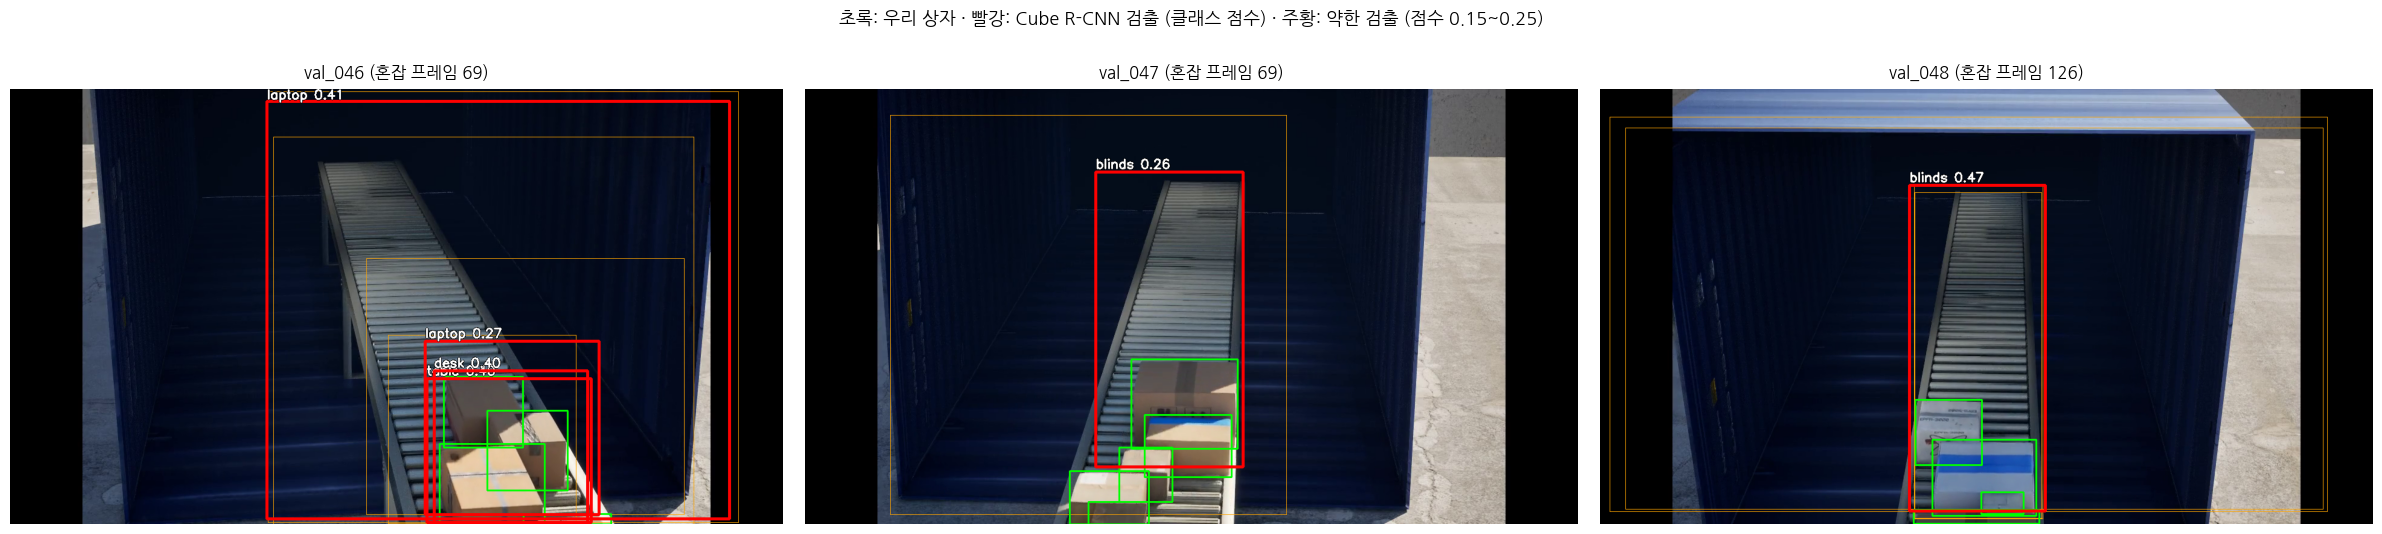

저장 → /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/baseline/cubercnn/val_detection_vis.png


In [15]:
# [V-1] 같은 프레임에서 우리 트랙 bbox(초록) vs Cube R-CNN 검출(빨강 · 주황)
import collections
SCORE_SHOW = 0.25                                         # 공식 demo.py 표시 기준
WEAK_MIN   = 0.15                                         # 이보다 낮은 점수는 그리지 않음 (화면이 너무 지저분해짐)
DET_VIDS   = [VIDS[46], VIDS[47] ,  VIDS[48]]    # 영상 3개 (바꿔도 됨)
MODE       = 'crowded'                                    # 'crowded': 상자가 가장 많이 보이는 프레임 · 'random': 무작위 프레임
RNG = random.Random(0)                                    # 무작위 프레임 고정 시드
SHOWN = {}                                                # 영상 → 그린 프레임 번호


def draw_frame(vid, mode):
    rec = TRACKS[vid]
    cnt = collections.Counter(int(fi) for t in rec['tracks'] for fi in t['fi'])
    fi = max(cnt, key=cnt.get) if mode == 'crowded' else RNG.choice(sorted(cnt))
    frame = fi * int(rec['step'])
    SHOWN[vid] = frame                                                 # [V-2]가 같은 프레임을 다시 씀
    cap = cv2.VideoCapture(video_path(SPLIT, vid)); cap.set(cv2.CAP_PROP_POS_FRAMES, frame)
    ok_, img = cap.read(); cap.release()
    ours = [t['bbox'][list(t['fi']).index(fi)] for t in rec['tracks'] if fi in set(int(x) for x in t['fi'])]
    boxes, scores, names = detect(img, focal_px_of(FOCAL[vid]))
    vis = img.copy()
    for b, s in zip(boxes, scores):                                    # 약한 검출
        if WEAK_MIN <= s < SCORE_SHOW:
            cv2.rectangle(vis, tuple(map(int, b[:2])), tuple(map(int, b[2:])), (0, 165, 255), 1)
    for b in ours:                                                     # 우리 상자
        cv2.rectangle(vis, tuple(map(int, b[:2])), tuple(map(int, b[2:])), (0, 255, 0), 2)
    for b, s, n in zip(boxes, scores, names):                          # Cube R-CNN 검출
        if s < SCORE_SHOW:
            continue
        x1, y1 = map(int, b[:2])
        cv2.rectangle(vis, (x1, y1), tuple(map(int, b[2:])), (0, 0, 255), 3)
        for color, th in (((0, 0, 0), 4), ((255, 255, 255), 2)):
            cv2.putText(vis, f'{n} {s:.2f}', (x1, max(y1 - 6, 16)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, th)
    return vis, frame


MNAME = {'crowded': '혼잡 프레임', 'random': '무작위 프레임'}[MODE]
fig, axes = plt.subplots(1, len(DET_VIDS), figsize=(8 * len(DET_VIDS), 5.4))   # 1행 × 3열
for ax, vid in zip(axes, DET_VIDS):
    vis, frame = draw_frame(vid, MODE)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f'{vid} ({MNAME} {frame})', fontsize=12, pad=8)
fig.suptitle(f'초록: 우리 상자 · 빨강: Cube R-CNN 검출 (클래스 점수) · 주황: 약한 검출 (점수 {WEAK_MIN}~{SCORE_SHOW})',
             fontsize=13, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(f'{OUT_DIR}/{SPLIT}_detection_vis.png', dpi=200, bbox_inches='tight'); plt.show()
print('저장 →', f'{OUT_DIR}/{SPLIT}_detection_vis.png')

### 같은 프레임에 Cube R-CNN이 추정한 3D 박스만 그리면
- [V-1]과 **같은 프레임**에서, 점수 ≥ 0.25인 검출마다 Cube R-CNN이 함께 출력한 **3D 박스(8개 꼭짓점)** 를 카메라 행렬로 화면에 투영해 그린다
- 우리 상자(초록)는 그리지 않는다 — 모델이 이 장면을 3D로 어떻게 보고 있는지만 보여준다

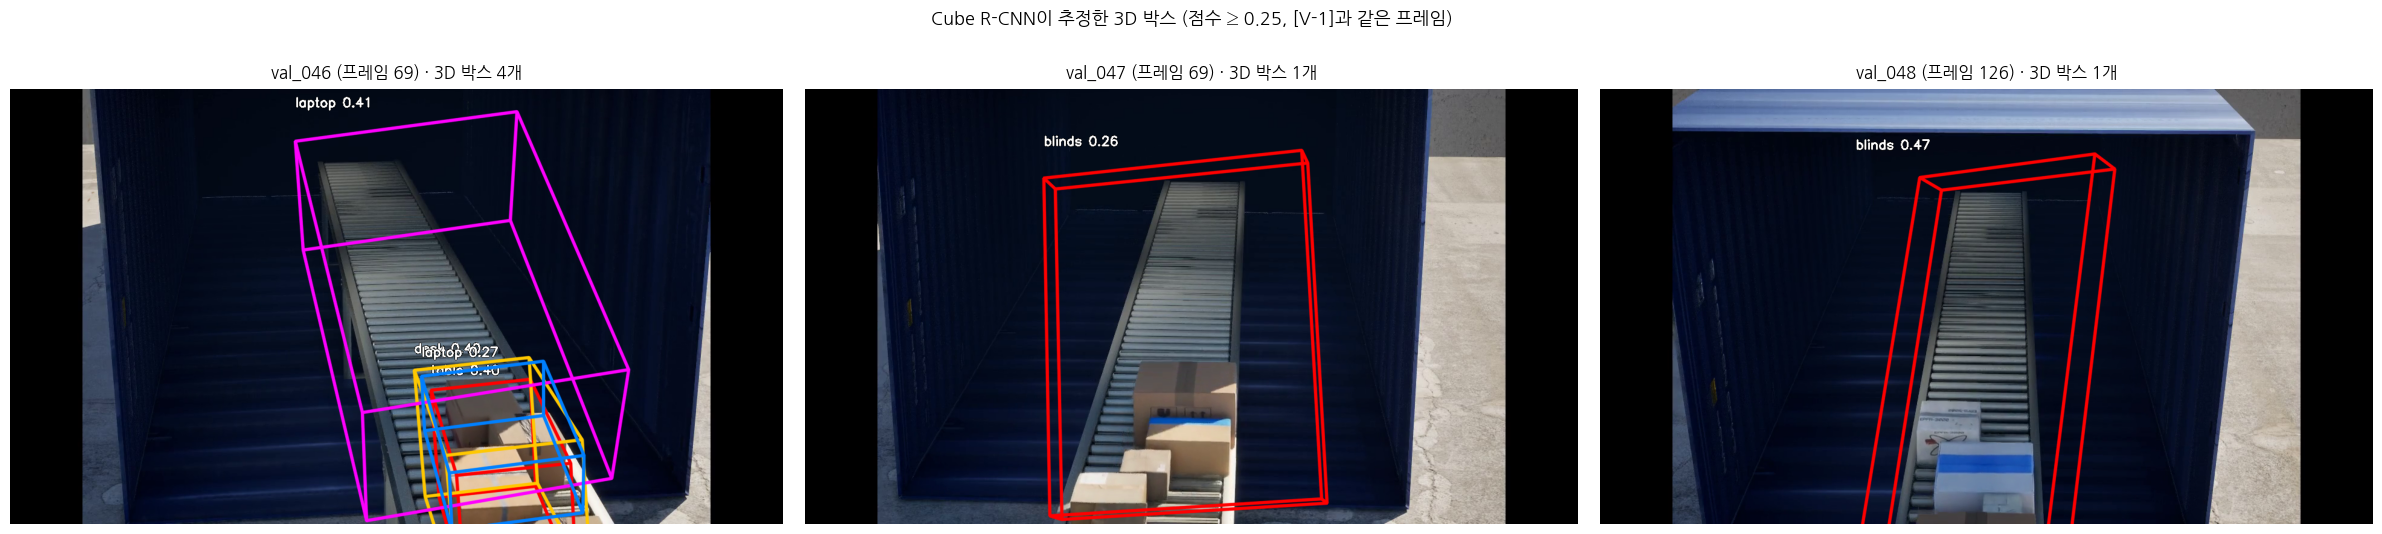

저장 → /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/baseline/cubercnn/val_detection_3d_vis.png


In [16]:
# [V-2] 같은 프레임에서 Cube R-CNN의 3D 박스 추정 결과만 (우리 상자 표시 없음)
#  - 3D 박스 꼭짓점(카메라 좌표, m)을 K로 투영: u = fx·X/Z + cx, v = fy·Y/Z + cy
#  - 꼭짓점 순서는 공식 코드(util.get_cuboid_verts_faces) 기준: 0-1-2-3 앞면, 4-5-6-7 뒷면
EDGES = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]
COLORS = [(0, 0, 255), (0, 200, 255), (255, 0, 255), (255, 128, 0), (0, 255, 255), (255, 255, 0)]   # 검출마다 다른 색 (BGR)


@torch.no_grad()
def detect_3d(img_bgr, f_px):
    # [L-2]의 detect와 같은 추론 + 3D 박스 꼭짓점 → [(점수, 클래스, 꼭짓점 8×3)], K
    H, W = img_bgr.shape[:2]
    K = np.array([[f_px, 0.0, W / 2], [0.0, f_px, H / 2], [0.0, 0.0, 1.0]])
    aug_in = T.AugInput(img_bgr); AUG(aug_in); image = aug_in.image
    inp = {'image': torch.as_tensor(np.ascontiguousarray(image.transpose(2, 0, 1))).cuda(),
           'height': H, 'width': W, 'K': K}
    ins = MODEL([inp])[0]['instances'].to('cpu')
    if len(ins) == 0:
        return [], K
    corners = ins.pred_bbox3D.numpy()
    if corners.ndim == 3 and corners.shape[1] == 3 and corners.shape[2] == 8:
        corners = corners.transpose(0, 2, 1)
    return list(zip(ins.scores.numpy(), [CATS[c] for c in ins.pred_classes.numpy()], corners)), K


def draw_cube(img, K, P, color, label):
    P = np.asarray(P, float)
    if (P[:, 2] <= 0.05).any():                       # 카메라 뒤쪽 꼭짓점이 있으면 투영이 뒤집혀서 생략
        return
    uv = (K @ P.T).T; uv = np.clip(uv[:, :2] / uv[:, 2:3], -5000, 5000).astype(int)
    for a, b in EDGES:
        cv2.line(img, (int(uv[a][0]), int(uv[a][1])), (int(uv[b][0]), int(uv[b][1])), color, 3, cv2.LINE_AA)
    x, y = int(uv[:, 0].min()), int(max(uv[:, 1].min() - 8, 18))
    for c, th in (((0, 0, 0), 4), ((255, 255, 255), 2)):
        cv2.putText(img, label, (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, th)


fig, axes = plt.subplots(1, len(DET_VIDS), figsize=(8 * len(DET_VIDS), 5.4))
for ax, vid in zip(axes, DET_VIDS):
    frame = SHOWN[vid]
    cap = cv2.VideoCapture(video_path(SPLIT, vid)); cap.set(cv2.CAP_PROP_POS_FRAMES, frame)
    ok_, img = cap.read(); cap.release()
    dets, K = detect_3d(img, focal_px_of(FOCAL[vid]))
    vis = img.copy()
    shown = [(s, n, P) for s, n, P in dets if s >= SCORE_SHOW]
    for k, (s, n, P) in enumerate(shown):
        draw_cube(vis, K, P, COLORS[k % len(COLORS)], f'{n} {s:.2f}')
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f'{vid} (프레임 {frame}) · 3D 박스 {len(shown)}개', fontsize=12, pad=8)
fig.suptitle(f'Cube R-CNN이 추정한 3D 박스 (점수 ≥ {SCORE_SHOW}, [V-1]과 같은 프레임)', fontsize=13, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(f'{OUT_DIR}/{SPLIT}_detection_3d_vis.png', dpi=200, bbox_inches='tight'); plt.show()
print('저장 →', f'{OUT_DIR}/{SPLIT}_detection_3d_vis.png')

# **3. 결론 — 그래서 OVMono3D-LIFT를 baseline으로**

> 📌 **Cube R-CNN의 한계 — 검출: 우리 상자를 제대로 검출하지 못한다**
> - `box`는 Cube R-CNN이 원래 검출하도록 학습된 클래스다 ([L-3]: 학습 클래스 50개 중 하나).
> - 그런데도 같은 프레임에 우리 트랙 bbox(초록)와 Cube R-CNN 검출(빨강)을 겹쳐 그리면, **상자 자체가 검출되지 않는다.**
> - 검출이 나오더라도 상자 하나하나가 아니라 여러 상자 · 컨베이어 · 컨테이너를 뭉뚱그린 큰 박스이고, 클래스도 `chair`, `camera`, `blinds`, `laptop`처럼 엉뚱하다.
> - Cube R-CNN은 실내 장면(Omni3D)으로 학습된 **closed-vocabulary** 모델이라, 컨베이어 위에 밀집한 상자를 '상자'로 찾지 못한다.

**→ 검출과 3D 추정을 분리한 모델이 필요하다.** Cube R-CNN은 2D 검출과 3D 추정이 한 모델에 묶여 있어서, 검출이 실패하면 3D도 얻을 수 없다.

**→ 그래서 최신 논문 baseline으로 OVMono3D-LIFT를 설정했다.** OVMono3D-LIFT는 **2D 검출 결과(bbox)를 넘겨주면 그 영역의 3D를 추정**하는 구조다 (검출과 3D lifting을 분리, class-agnostic 3D head). 따라서 우리 트래킹 bbox를 그대로 넘겨주고, **검출 능력 차이 없이 3D 치수 추정 능력만** 공정하게 비교할 수 있다.